
# makemore: part 3

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
import time
import numpy as np
import random
import torch.nn as nn

device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
# elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
#    device = "mps:0"

print(f"Running on {device}")


Running on cpu


In [3]:

### build the dataset
block_size = 1
T = 32
end_char = '_' 
batch_size = 128

DATA = "words"
DATA = "shakespaere"

if DATA == "words": # read in all the words
    with open("data/names.txt", "r") as f:
        words = f.readlines()
    words = [word.strip() for word in words]
    #random.seed(42)
    random.shuffle(words)
    if end_char in "".join(words): exit(f"the character '{end_char}' is already in the vocabulary")
    text = "_".join(words)
elif DATA == "claire":
    ########### LOAD FROM DATASET
    from datasets import load_dataset
    import re
    import unicodedata

    # Login using e.g. `huggingface-cli login` to access this dataset
    ds = load_dataset("OpenLLM-France/Claire-Dialogue-French-0.1")

    dialogues = [el['text'] for el in ds['train']]

    # Refomating
    to_remove_c = "µ"
    dialogues = [el.replace(to_remove_c, "") for el in dialogues]
    dialogues = [re.sub(r'\[.*?\] ', '', el) for el in dialogues]
    dialogues = [unicodedata.normalize('NFKD', el).encode('ascii', 'ignore').decode('utf-8') for el in dialogues]

    print(dialogues[0][:100])
    print(len(dialogues), "dialogues loaded")

    start_word = 0

    #### SPLITS
    for i in range (1000):
        if sum(len(w) + 1 for w in dialogues[start_word:start_word+i]) > 2000_000:
            words = dialogues[start_word:start_word+i]
            print( i,"cut at", i + start_word, "dialogues with ", sum(len(w) + 1 for w in words), "characters")
            start_word += i
            break
elif DATA == "shakespaere":
    with open("data/tiny_shakespeare.txt", "r") as f:
        text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string



class DataLoader:
    def __init__(self, data):
        self.data = data.to(device)
        self.reset()
        self.easy_mode = False
        #Xb, targets = Xb.to(device), targets.to(device)

    def reset(self):
        self.batch_reset = True
        self.index = random.randint(0, T)

    def get_batch(self):
        buf = self.data[self.index : self.index+batch_size*T+1]
        x = (buf[:-1]).view(batch_size, T) # inputs
        y = (buf[1:]).view(batch_size, T) # targets

        self.index += batch_size * T
        if self.index + batch_size * T + 1 > len(self.data):
            self.reset()
        return x, y


# Train and test splits
data = torch.tensor(encode(text))#, dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
DLtr = DataLoader(data[:n])
DLte = DataLoader(data[n:])
print(f"vocab size {vocab_size} ,loaded {n} tokens : {n//batch_size} Time learning - {n//(batch_size * T)} batches")

# show first 5 examples
xb, yb = DLtr.get_batch()
print(f"ex : {decode(xb[0][:30].tolist())}")
for i in range(15,20):
    x = xb[:, i:i+block_size]
    y = yb[:, i+block_size - 1]
    #print(x, y)
    for b in range(2):
        print("X", i, ":", decode(x[b].tolist()), '-->', decode([y[b].tolist()]), end = "      \t\t")
    print()

for i in range(100):
    x, y = DLtr.get_batch()
    
    #print("X", i, ":", decode(x[0].tolist()), '-->', decode([y[0].tolist()]))
    assert x.shape == (batch_size,T), x.shape 
    assert y.shape == (batch_size,T), "mlkjqmlkdjf"
    assert (0 <= x).all() and  (x < vocab_size).all()
    assert (0 <= y).all() and (y < vocab_size).all()


DLtr.reset()


vocab size 65 ,loaded 1003854 tokens : 7842 Time learning - 245 batches
ex : tizen:
Before we proceed any f
X 15 : e -->        		X 15 : p --> e      		
X 16 :   --> p      		X 16 : e --> a      		
X 17 : p --> r      		X 17 : a --> k      		
X 18 : r --> o      		X 18 : k --> .      		
X 19 : o --> c      		X 19 : . --> 
      		


# MODEL

In [46]:
def myprint(t, name):
    print(f"{name:<10} : {tuple(t.shape)} ")#: {t[:1].tolist()}")


torch.set_default_dtype(torch.float32)


# -----------------------------------------------------------------------------------------------

class Embedding(nn.Module): # for each vocab index, look up the corresponding vector in a table
    def __init__(self, num_embeddings, embedding_dim):
        super().__init__()
        self.weight = torch.randn((num_embeddings, embedding_dim))
        self.weight_grad = torch.zeros_like(self.weight)
        self.IX = torch.zeros(32)

        
    def __call__(self, IX): # IX : (Batch, T(Time))
        self.IX = IX
        self.out = self.weight[IX] 
        return self.out # (B, T, C : channel)
    
    
    def parameters(self):
        return [self.weight]
    def gradients(self):
        return [self.weight_grad]
    
    def backward(self, delta):
        IX = self.IX
        flattened_indices = IX.view(-1)  # Shape: (Batch * T)
        flattened_delta = delta.view(-1, delta.shape[-1])  # Shape: (Batch * T, Embedding_dim)
        self.weight_grad.index_add_(0, flattened_indices, flattened_delta)

        return self.weight_grad
    
    def to(self, device):
        print("emebed to ", device)
        self.weight = self.weight.to(device)
        self.weight_grad = self.weight_grad.to(device)
        if self.IX is not None:
            self.IX = self.IX.to(device)
        return self
    
# PYTORCHIFYING -----------
class Linear(nn.Module):
    
    def __init__(self, fan_in, fan_out, bias=True):
        super().__init__()
        # kaiming initialization : 
        self.weight = torch.randn((fan_in, fan_out)) * (2/(fan_in+fan_out)) 
        self.bias = torch.zeros(fan_out) if bias else None
        self.weight_grad = torch.zeros_like(self.weight)
        self.bias_grad = torch.zeros_like(self.bias) if bias else None
    
    def __call__(self, x):
        self.x = x
        self.out = x @ self.weight
        if self.bias is not None:        
            self.out += self.bias
        return self.out
    
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])
    
    def gradients(self):
        return [self.weight_grad] + ([] if self.bias is None else [self.bias_grad])
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T, fan_out)
        if x is None: x = self.x

        if grad:
            if self.bias is not None:
                self.bias_grad += delta.sum(dim=tuple(range(delta.ndim - 1)))

            x_reshaped = x.view(-1, x.shape[-1])  # Shape: (B * T, D)
            delta_reshaped = delta.view(-1, delta.shape[-1])  # Shape: (B * T, C)
            self.weight_grad += x_reshaped.T @ delta_reshaped  # Shape: (fan_in, fan_out)

        x_grad = delta @ self.weight.T # x grad : (batch, fan_in)
        return x_grad

    def to(self, device):
        self.device = device  # Set the device attribute
        self.weight = self.weight.to(device)
        self.weight_grad = self.weight_grad.to(device)
        if self.bias is not None:
            self.bias = self.bias.to(device)
            self.bias_grad = self.bias_grad.to(device)
        return self
    
# -----------------------------------------------------------------------------------------------
class LayerNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps # for numerical stability
        self.dim = dim
        # parameters (trained with backprop)
        self.gamma = torch.ones(dim) # (dim)
        self.beta = torch.zeros(dim) # (dim)

        # gradients : doesn't need to be saved : so use
        self.gamma_grad = torch.zeros_like(self.gamma)
        self.beta_grad = torch.zeros_like(self.beta)

    
    def __call__(self, x):
        self.compute_mms(x)
        self.out = self.gamma * (self.mu * self.sigma_inv) + self.beta
        return self.out
    
    def compute_mms(self, x):
        # calculate the forward pass
        self.xmean = x.mean(dim=-1, keepdim=True)
        self.mu = x - self.xmean
        xvar = x.var(dim=-1, unbiased=False, keepdim=True)
        self.sigma_inv = torch.sqrt(xvar + self.eps)**(-1) # normalize to unit variance
        
    
    def parameters(self):
        return [self.gamma, self.beta]
    
    def gradients(self):
        return [self.gamma_grad, self.beta_grad]
    
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T ..., dim)
        if x is not None:
            self.compute_mms(x)
        mu, sigma_inv, gamma = self.mu, self.sigma_inv, self.gamma

        if grad:
            self.beta_grad += delta.sum(dim=tuple(range(delta.ndim - 1)))
            self.gamma_grad += (delta * mu * sigma_inv).sum(dim=tuple(range(delta.ndim - 1)))  # sum over batch : (dim)  
        
        # b:batch, h:hidden
        delta = (
            delta*gamma.unsqueeze(0) * sigma_inv
            - 1/self.dim * (torch.einsum('...h,h,...i->...', [delta, gamma, sigma_inv]).unsqueeze(-1) 
                 + mu * torch.einsum('...h,h,...h,...i->...', [delta, gamma, mu, sigma_inv**(3)]).unsqueeze(-1))
        ) 
        return delta # delta : (batch, dim)
    
    def to(self, device):
        self.gamma = self.gamma.to(device)
        self.beta = self.beta.to(device)
        self.gamma_grad = self.gamma_grad.to(device)
        self.beta_grad = self.beta_grad.to(device)
        return self
    
  
# -----------------------------------------------------------------------------------------------

class Tanh(nn.Module):
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):return []
    def gradients(self):return []
    def to(self, device): return self
    def backward(self, delta, x=None, grad=True):
        if x is not None:
            self.__call__(x)
        return delta * (1 - self.out**2)


# -----------------------------------------------------------------------------------------------

class Flatten(nn.Module):
    def __init__(self, input_shape, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.input_shape = input_shape

    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    
    def parameters(self): return []
    def gradients(self): return []
    def to(self, device): return self
    def backward(self, delta): 
        return delta.view(self.input_shape)
    

    
# -----------------------------------------------------------------------------------------------

# model class for looping over a layer
# this class is STATEFUL, it keeps track of the hidden state
class Loop(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.layers = [ Linear(input_dim + hidden_dim, hidden_dim + output_dim, bias=True), 
                        LayerNorm(hidden_dim + output_dim), Tanh()]
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.hidden_dim = hidden_dim

        self.initial_h = torch.randn(1, hidden_dim)  # initialize hidden state to zeros
        self.initial_h_grad = torch.zeros_like(self.initial_h)

        self.no_direct_input = False
        self.no_loop = False
        self.device = None

        self.reset_state()
        self.set_T()

    def set_T(self):
        self.saved_x = []
        ## INPUT : (B,T,inp) -> (B,inp) -> (B, inp + hidden) 
        xt = torch.zeros(batch_size, self.input_dim + self.hidden_dim, device=self.device)
        for l in self.layers:
            self.saved_x.append(torch.zeros(xt.shape[0], T, *xt.shape[1:], device=self.device))
            xt = l(xt)

    def reset_state(self):
        #backward state
        self.dgrad = torch.zeros(batch_size, self.hidden_dim, device=self.device)
        # initialize hidden state : (different hidden state for each example in the batch)
        self.h = self.initial_h.expand(batch_size, -1) # (batch, hidden_dim)


    def __call__(self, x): # x : (batch, T, input_dim) and h : (1, hidden_dim)
        # LOOP over all the times
        T = x.shape[1]
        y = torch.zeros(batch_size, T, self.output_dim, device=self.device)
        for t in range(T): # loop over all the times
            xt = x[:,t]
            yt, self.h = self.forward_T(xt, self.h, t)
            if self.no_loop: self.h = torch.zeros_like(self.h)
            y[:,t] = yt
        return y

    def forward_T(self, xt, h, t): # x : (batch, input_dim) and h : (1, hidden_dim)
        # CONCATENATE input and previous hidden state
        if self.no_direct_input:
            inp = torch.cat([torch.zeros_like(xt), h], dim=-1) # (batch, input_dim + hidden_dim)
            out = self.forward_T_layers(inp, t) # (batch, output_dim + hidden_dim)
            y, _ = out.split([self.output_dim, self.hidden_dim], dim=-1) # (batch, hidden_dim), (batch, output_dim)
            
            inp = torch.cat([xt, h], dim=-1) # (batch, input_dim + hidden_dim)
            out = self.forward_T_layers(inp, t) # (batch, output_dim + hidden_dim)
            _, h = out.split([self.output_dim, self.hidden_dim], dim=-1) # (batch, hidden_dim), (batch, output_dim)
        else:
            inp = torch.cat([xt, h], dim=-1) # (batch, input_dim + hidden_dim)
            out = self.forward_T_layers(inp, t) # (batch, output_dim + hidden_dim)
            y, h = out.split([self.output_dim, self.hidden_dim], dim=-1) # (batch, hidden_dim), (batch, output_dim)
        return y, h
    
    def forward_T_layers(self, xt, t): # SEQUENTIAL over the layers (and save the x)
        for i, l in enumerate(self.layers):
            # print(dl_t.device, ' brefore' , l.__class__.__name__ )
            self.saved_x[i][:,t] = xt
            xt = l(xt)
        return xt
    
    def parameters(self):
        #return self.layer.parameters() # 
        return [p for l in self.layers for p in l.parameters()] + [self.initial_h]
    
    def gradients(self):
        return [g for l in self.layers for g in l.gradients()] + [self.initial_h_grad]
        return self.layer.gradients()# 
    
    def backward(self, delta): # (B, T, out dim)
        T = delta.shape[1]
        delta_out = torch.zeros(batch_size, T, self.input_dim, device=self.device)
        for t in range(T-1, -1, -1):
            delta_t = delta[:,t]
            delta_out_t = self.backward_T(delta_t, t)
            delta_out[:,t] = delta_out_t
        return delta_out

    def backward_T(self, delta_t, t):
        if self.no_direct_input:
            dldOut = torch.cat([torch.zeros_like(delta_t), self.dgrad], dim=-1)
            dldIn = self.backward_T_layer(dldOut, t, grad=False)
            delta_out, _ = dldIn.split([self.input_dim, self.hidden_dim], dim=-1)

            dldOut = torch.cat([delta_t, self.dgrad], dim=-1)
            dldIn = self.backward_T_layer(dldOut, t)
            _, self.dgrad = dldIn.split([self.input_dim, self.hidden_dim], dim=-1)
        else:
            dldOut = torch.cat([delta_t, self.dgrad], dim=-1)
            dldIn = self.backward_T_layer(dldOut, t)
            delta_out, self.dgrad = dldIn.split([self.input_dim, self.hidden_dim], dim=-1)
        if self.no_loop: self.dgrad = torch.zeros_like(self.dgrad)

        if t == 0:
            self.initial_h_grad += self.dgrad.sum(dim=0)
        return delta_out
    
    def backward_T_layer(self, dl_t, t, *args):

        for i in range(len(self.layers)-1, -1, -1):
            l = self.layers[i]
            # print(dl_t.device, ' brefore' , l.__class__.__name__ )
            dl_t = l.backward(dl_t, x= self.saved_x[i][:,t], *args)
        return dl_t

    
    def to(self, device):
        self.device = device
        self.layers = [l.to(device) for l in self.layers]
        self.initial_h = self.initial_h.to(device)
        self.initial_h_grad = self.initial_h_grad.to(device)
        self.h = self.h.to(device)
        self.dgrad = self.dgrad.to(device)
        self.saved_x = [x.to(device) for x in self.saved_x]
        return self
                                     

# -----------------------------------------------------------------------------------------------
class Sequential(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.layers = layers
    
    def __call__(self, x):
        for layer in self.layers:
            #print(f"{layer.__class__.__name__} : {x.device}")
            x = layer(x) 
        return x
    
    def parameters(self):
        # get parameters of all layers and stretch them out into one list
        return [p for layer in self.layers for p in layer.parameters()]
    
    def gradients(self):
        return [p for layer in self.layers for p in layer.gradients()]
    
    def backward(self, delta):
        for layer in reversed(self.layers):
            # print(delta.device, ' brefore' , layer.__class__.__name__ )
            delta = layer.backward(delta)
        return delta
    
    def to(self, device):
        self.layers = [l.to(device) for l in self.layers]
        return super().to(device)

  
# -----------------------------------------------------------------------------------------------



    
    




In [47]:

n_embd = 40 # the dimensionality of the character embedding vectors
n_hidden = 256 # the number of neurons in the hidden layer of the MLP
n_out_hidden = n_embd
###
total_steps, train_index, train_time = 0, 0, 0
lossi = [] # store loss values

#B : batch, T : Time : C : Channel
#B = batch_size
#T = block_size
#C = n_embd

CMP = False
torch.set_grad_enabled(CMP)
torch.manual_seed(42)

LOOP = True

if LOOP:
    loopLayer = Loop(input_dim=n_embd, output_dim=n_out_hidden, hidden_dim=n_hidden)
    
    #Flatten(input_shape=(batch_size, T, block_size)),  # (B, T*C)
    model = Sequential([                # (B, T)
        Embedding(vocab_size, n_embd),  # (B, T, C)
        loopLayer,         # loop of T : (B, t  C) -> (B, t, C_h)
        Linear(n_out_hidden, vocab_size) # (B, T, Vocab size)
    ])
    loop_w = loopLayer.layers[0].weight
else:
    #Flatten(n_embd),
    model = Sequential([
        Embedding(vocab_size, n_embd), 
        Linear(n_embd , n_hidden, bias=True), LayerNorm(n_hidden), Tanh(),  
        Linear(n_hidden, vocab_size)
    ])
    loopLayer = None
# with torch.no_grad():
#     last layer: make less confident
#     model.layers[-1].weight *= 0.1
#     model.layers[-1].bias *= 0.1
#   all other layers: apply gain
#   for layer in model.layers[:-1]:
#     if isinstance(layer, Linear):
#       layer.weight *= 0.5 #* 5/3

gradients, parameters = model.gradients(),  model.parameters()
p_name = [f"{layer.__class__.__name__} : {tuple(p.shape)}" for layer in model.layers for p in layer.parameters() ]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
print(f"Parameters by layer :\n" + "\n".join([f"{sum(p.nelement() for p in layer.parameters())}\t   {layer.__class__.__name__} \t  {[tuple(p.shape) for p in layer.parameters()]}  " for layer in model.layers]))

if CMP:
    for p in parameters:
        p.requires_grad = True

def backward_cross_entropy(_y, _Yb): # cross entropy loss backward pass
    dy = F.softmax(_y, dim=-1)
    dy[torch.arange(_y.size(0)), _Yb] -= 1
    dy /= batch_size
    return dy




94025
Parameters by layer :
2600	   Embedding 	  [(65, 40)]  
88760	   Loop 	  [(296, 296), (296,), (296,), (296,), (1, 256)]  
2665	   Linear 	  [(40, 65), (65,)]  


In [48]:
# same optimization as last time
steps = 2_000
if loopLayer is not None:
    loopLayer.no_direct_input = False
    loopLayer.no_loop = False

model = model.to(device)

for p, g in zip(model.parameters(), model.gradients()):
    g = None

batch_size = 256
T = 128 #128
loopLayer.set_T()

#model = model.to(device)
total_steps = len(lossi)
steps = steps - total_steps % steps 
total_steps += steps
start_time = time.time()
#DLtr.reset()
model.train()
EASY = False
DLtr.easy_mode, DLte.easy_mode = EASY, EASY
for i in range(steps):
    # minibatch construct : sample a random subset of the data
    if DLtr.batch_reset:
        #if loopLayer is not None:
        #    loopLayer.reset_state()
        DLtr.batch_reset = False
        #print(f"BATCH RESET")
    if loopLayer is not None:
        loopLayer.reset_state()
    Xb, targets = DLtr.get_batch() # (B, T)
    
    # forward pass
    y = model(Xb) # y : (B, T, Vocab size)
    
    targets = targets.view(-1) # (B * T)
    y = y.view(-1, vocab_size) # (B * T, vacab)vocab_size
    loss = F.cross_entropy(y, targets) # y needs to be (B * T, C)


    ############# backward pass ################
    for p, g in zip(model.parameters(), model.gradients()):
        if CMP: p.grad = None # zero all the gradients in the model
        g.fill_(0.0) # zero all the gradients in the model
    
    if CMP: 
        y.retain_grad() 
        loss.backward() # backpropagate the error
        cmp("dy", dy, y.grad, only_errors=True)

    dy = backward_cross_entropy(y, targets)
    dy = dy.view(batch_size, T, -1) # (B, T, C)
    delta = model.backward(dy)

    ##################################################

    # update
    lr = 0.0001 if train_index < 1800 else 0.00002 # step learning rate decay    
    
    for p, g, name in zip(model.parameters(), model.gradients(), p_name):
        #p.data += -lr * p.grad
        if CMP: cmp(name, p.grad, g, only_errors=True)
        p.data += -lr * g
    

    # track stats
    lossi.append(loss.log10().item())
    if i % (steps//10) == 0: # print every once in a while
        dt = time.time() - start_time
        start_time = time.time()
        train_time += dt
        processed_tokens = (steps//10) * batch_size * T
        average_loss = sum(lossi[-(steps//10):])/len(lossi[-(steps//10):])
        print(f'{train_index:7d}/{total_steps:7d}:  {average_loss:.4f} - {10**average_loss:.4f}  ({train_time:.0f}s : +{dt:.0f}s)  {processed_tokens / (dt*1e3):.0f} k tok/s')
    
    train_index += 1
print(f"Training time: {train_time:.0f} seconds")





emebed to  cpu
      0/   2000:  0.6206 - 4.1742  (0s : +0s)  26142 k tok/s


KeyboardInterrupt: 

mean tensor(0.0051)
100.0 % non zero weights
20% threshold: 0.002165751298889518


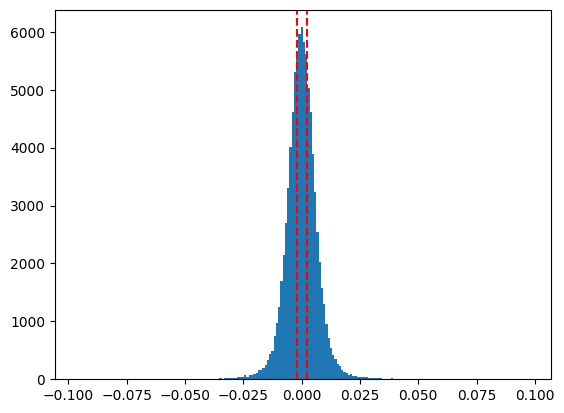

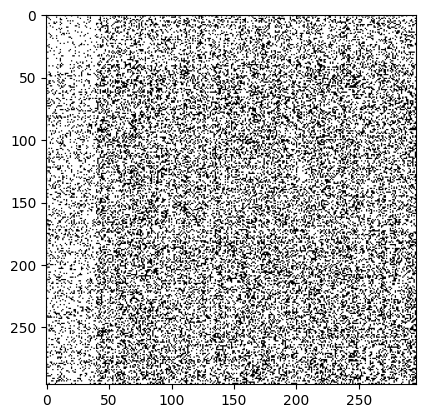

In [ ]:

# loop_w = loop_w_saved.clone()
# loop_w[torch.abs(loop_w) < 0.02] = 0
# #loop_w_saved = loop_w.clone()
# loopLayer.layers[0].weight = loop_w

if loopLayer is not None:
    #loop_w[:n_embd * block_size, :n_out_hidden] = 0
    #plt.imshow(loop_w)
    print("mean", loop_w.abs().mean())
    print(f"{loop_w.count_nonzero()/ loop_w.nelement() *100} % non zero weights")
    
    
    # calculate the 20% threshold
    threshold = np.percentile(loop_w.abs().cpu().numpy(), 30)
    print(f"20% threshold: {threshold}")

    plt.hist(loop_w.flatten().cpu().numpy(), bins=200)
    plt.axvline(x=-threshold, color='r', linestyle='--')
    plt.axvline(x=threshold, color='r', linestyle='--')
    plt.show()


    # represent 20 % that are the closest to 0
    plt.imshow(torch.abs(loop_w) < threshold, cmap= 'binary')
    plt.show()



# 8000 steps, 1537s (Batch: 256, block: 1, lr: 2e-05, hidden: 256) : 2.1840781529744464
# train loss : 2.1090   	 acc 42.9% 	 prob 24.5%     (log:0.3240776580869541)
# test  loss : 2.1841  	 acc 40.3% 	 prob 23.5%
Overfitting : 0.07507291634877511


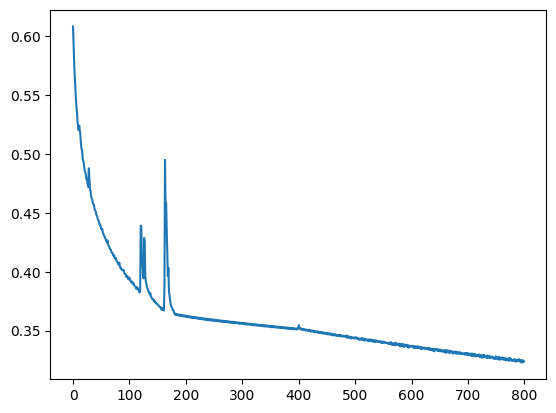

In [ ]:
if loopLayer is not None:
    loopLayer.no_direct_input = False
    loopLayer.no_loop = False

#  Evaluate the model
@torch.no_grad()  # Disable gradient tracking
def split_loss_and_accuracy(DL, n_iteration=30):
    avg_loss = 0
    correct_predictions = 0
    total_predictions = 0
    avg_correct_prob = 0
    
    for i in range(n_iteration):
        # Get the input and target sequences
        x, y = DL.get_batch()  # Fetch data batch
        if loopLayer is not None: loopLayer.reset_state()
        
        # Forward pass through the model
        x = model(x)  # Output logits
        x = x.view(-1, vocab_size)  # Reshape logits for loss computation
        y = y.view(-1)  # Flatten targets

        # Compute loss
        avg_loss += F.cross_entropy(x, y, reduction='mean').item()

        # Compute accuracy
        predictions = torch.argmax(x, dim=1)  # Predicted class indices
        correct_predictions += (predictions == y).sum().item()  # Count correct predictions
        total_predictions += y.size(0)  # Count total predictions
        
        proba = F.softmax(x, dim=1)
        correct_probs = proba[torch.arange(y.size(0)), y]  # Correct class probabilities
        avg_correct_prob += correct_probs.mean().item()

    avg_loss /= n_iteration  # Average the loss over iterations
    accuracy = correct_predictions / total_predictions  # Compute accuracy
    avg_correct_prob /= n_iteration
    return avg_loss, accuracy, avg_correct_prob

trl, tracc, tr_prob = split_loss_and_accuracy(DLtr)

test, teacc, te_prob = split_loss_and_accuracy(DLte)

print(f"# {total_steps} steps, {train_time:.0f}s (Batch: {batch_size}, block: {block_size}, lr: {lr}, hidden: {n_hidden}) : {test}")
print(f"# train loss : {trl:.4f}   \t acc {tracc * 100:.1f}% \t prob {tr_prob * 100:.1f}%     (log:{np.log10(trl)})")
print(f"# test  loss : {test:0.4f}  \t acc {teacc * 100:.1f}% \t prob {te_prob * 100:.1f}%")


print(f"Overfitting : {test - trl}")
if test - trl > 0.1:
    print("\033[91mModel is overfitting\033[0m")

spliter = 10**int(np.log10(len(lossi))-2)

plt.plot(torch.tensor(lossi).view(-1, spliter).mean(1));

# 1 letter

# LOOP  
# # 13000 steps, 708s (Batch: 32, block: 1, lr: 0.01, hidden: 64) : 2.0660481452941895
# train loss : 2.0372254848480225      (log:0.30903910038242466)  
#  test  loss : 2.0660
# 2000 steps, 420s (Batch: 32, block: 1, lr: 0.001, hidden: 256) : 2.0285587986310323
#  train loss : 1.9258   	 acc 45.7% 	 prob 29.6%     (log:0.2846129310450921)
# test  loss : 2.0286  	 acc 42.0% 	 prob 28.2%
## ON shakespaere
# 5700 steps, 972s (Batch: 64, block: 1, lr: 1e-05, hidden: 256) : 1.9928557395935058
# train loss : 1.8798   	 acc 47.4% 	 prob 30.6%     (log:0.27412079568294734)
# test  loss : 1.9929  	 acc 43.3% 	 prob 28.8%




In [45]:
# sample from the model
model.eval()
g = torch.Generator(device=device).manual_seed(2147483647 + 10)

def generate_from(model, x, max_tokens=1000):
    # x : (B,T)
    if loopLayer is not None:
        loopLayer.reset_state()

    for i in range(max_tokens):
        inp = x[:,i:i+1]
        y = model(inp).view(-1, vocab_size)
        # print(y.shape)
        if i +1 >= x.shape[1]:
            probs = F.softmax(y, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g)
            x = torch.cat([x, ix], dim = 1)
    return x

#x = DLte.get_batch()[0][:, 0:1]
x = torch.asarray([encode("MENENIUS:\nThe senators of Rome are this good belly,") for _ in range(batch_size)]).to(device)

out = generate_from(model, x, max_tokens=1000)

for txt in out[:1]:
    txt = txt.tolist()
    print( f"{len(txt)} tokens :", decode(txt)) #.replace(end_char, " "))
    

1001 tokens : MENENIUS:
The senators of Rome are this good belly, geid,
3 Ifleb sosgtectF mate hey ti3

kPthorgh the cofthy is thinn
Ocinh,hat wopltiyX for
MQoGess that theinen UQNssLartA zthee goool to houte& sor,
-engoo, tuico in tyimeld aed andull I ar hl'f yam be it:
-lzy thiolgsl yebeox:
Mhe hurmnq,houdd you fon?
hnme, ad thi'd bfeace,S
Buw the cDarWhiluse dosm
poonty lad,
And Ir to bafe nocd obl lepmonducvest been to cer
For lajry ties meoandime't were potheersGwURprSeuve mi,
?rn:z, now thou masby.

WIILACz:lY.

TVfied heaws the t-DaCmedye ule this lopltolles's sekt mofis new afments agame sorele,Q you cwar3

jROvaIith palolrsalt tham
DhitosJ thor mfrenitheug, w-owaw horrhoy daew Ivesds im benhis oryess am& aple
De &eunint alding ozs atveusy olaofe,
Oet I nog Ifep as wiale pQeo
COyqnebood lordngiro$y-veusl. KORK
The !oubleX now imidere't untertoLk
Becelle?
The ciwt, bsGime
Yeas fnrenow. 
KRER-:
Theer hoyp laL:
Bis urn ma'd shagls, Id'd.re with reX
X 3
Mj$X
Dhyther blebdeke misCmh

In [ ]:

    
b, h = 2, 3
ln = LayerNorm(h)
#ln = torch.nn.LayerNorm(h)
#torch.manual_seed(19)
x = torch.randn(b, h) * 10+ 100
y = torch.randn(b, h)

myprint(x, "x")
myprint(y, "y")

for p in ln.parameters() + [x]:
    p.requires_grad = True
    p.grad = torch.zeros_like(p)

pred = ln(x)
delta = (pred - y)#.sum()
loss = delta.sum()

#loss.backward()

print("loss", loss)

dlddelta = torch.ones_like(pred)
out_delta = ln.backward(dlddelta)

def cmp(s, a, b, only_errors=False):
    app = torch.allclose(a, b, atol=1e-7)
    if only_errors and app: return
    ex = torch.all(a == b).item()
    maxdiff = (a - b).abs().max().item()
    app_color = '\033[92m' if app else '\033[91m'
    exact_color = '\033[92m' if ex else '\033[91m'
    print(f'{s:15s} | {exact_color}exact: {str(ex):5s} {app_color}| approximate: {str(app):5s} | maxdiff: {maxdiff}\033[0m')
    if (a == torch.zeros_like(a)).all() or (b == torch.zeros_like(b)).all():
        print(f"WARNING : ZEROS : a {a.tolist()} and b {b.tolist()}")

for p, g in zip(ln.parameters() + [x], ln.gradients() + [out_delta]):
    cmp("layernorm param", p.grad, g)


x          : (2, 3) 
y          : (2, 3) 
loss tensor(2.5384)
layernorm param | exact: False | approximate: False | maxdiff: 2.278244733810425
layernorm param | exact: False | approximate: False | maxdiff: 2.0
layernorm param | exact: False | approximate: True  | maxdiff: 5.960464477539063e-08
